# EpiProtAge quickstart

Score the samples of a public mouse proteome with the zero-shot brain aging clock. The example is the whole-brain proteome of Scifo et al. 2025 (PXD058684): 45 mice aged 3 to 26 months, 4,714 proteins with gene symbols, log intensities, and a row `age` with the ages in months. The clock was not fitted on this cohort. Besides EpiProtAge the notebook needs `matplotlib` and `jupyter`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

import epiprotage as ep

table = pd.read_csv("data/scifo2025_whole_brain.csv")
table.iloc[:4, :5]

,symbol,c3662,c2295,c1358,c1364
0,Tuba1c,33.783,33.303,33.863,33.754
1,Tubb2a,33.988,33.432,33.879,33.563
2,Actg1,33.459,33.651,33.460,33.489
3,Mbp,32.997,32.822,32.937,33.356


Score the samples. The first column holds the gene symbols; the row `age` is used for the correlation.

In [2]:
result = ep.score(table, species="mouse")
print(result.attrs)
result.head()

{'species': 'mouse', 'ids': 'symbol', 'genes_matched': 4421, 'genes_input': 4714, 'spearman_rho': 0.7529634162427457, 'spearman_p': 2.422678128227811e-09}


,sample,score,n_genes_matched,age
0,c3662,-0.126800,4281,8.0
1,c2295,-1.335628,4021,8.0
2,c1358,-0.334468,4279,8.0
3,c1364,-0.421146,4248,8.0
4,c1378,0.182703,4266,8.0


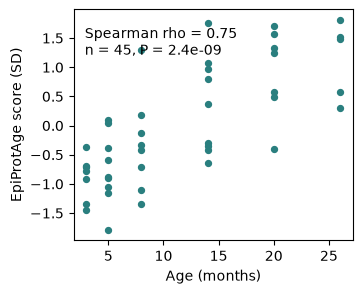

In [3]:
rho, p = result.attrs["spearman_rho"], result.attrs["spearman_p"]
fig, ax = plt.subplots(figsize=(3.6, 3))
ax.scatter(result.age, result.score, s=18, color="#2a7f7f")
ax.set(xlabel="Age (months)", ylabel="EpiProtAge score (SD)")
ax.text(0.04, 0.93, f"Spearman rho = {rho:.2f}\nn = {len(result)}, P = {p:.1e}", transform=ax.transAxes, va="top")
plt.show()

The proteins with the largest weights among those quantified in the data. Each gene has a predicted age z (`weight`), the age z observed in the training cohorts and its number of m6A sites.

In [4]:
w = ep.weights("mouse").set_index("symbol")
quantified = w.loc[w.index.intersection(table.iloc[:, 0])]
pd.concat([quantified.nlargest(5, "weight"), quantified.nsmallest(5, "weight")]).drop(columns="gene_id")

,weight,observed_z,m6A_sites
symbol,,,
Hexb,8.418541,7.580374,0
Bcas1,8.075613,1.795837,1
Cryab,7.767546,3.564854,2
Gsn,7.203953,5.988343,3
Anxa2,6.863315,4.480582,0
Lsamp,-5.744840,-7.152687,7
Ntm,-5.323137,-6.577112,23
Negr1,-4.905402,-7.670115,10
Cadm2,-4.454506,-4.898864,10


In [5]:
ep.gene("Gfap", "mouse")

gene_id       ENSMUSG00000020932
symbol                      Gfap
weight                  4.780748
observed_z               9.98879
m6A_sites                      6
Name: 1878, dtype: object

The score is relative to this upload (mean 0, SD 1), so it ranks the 45 samples; it is not an age in years. The same call works on a file (`ep.score("proteome.csv", "mouse")`), and `epiprotage score proteome.csv --species mouse` on the command line. Weights version:

In [6]:
ep.weights_version()

{'date': '2026-10-17',
 'git_commit': 'a558ea9f',
 'mouse': {'genes': 10606,
  'weights_computed': '2026-10-17',
  'sha256': 'a0def2e762c9a070'},
 'human': {'genes': 9990,
  'weights_computed': '2026-10-17',
  'sha256': '58204128f165b629'}}